# UCS420: Cognitive Computing — Lab Assignment 7
## E-Commerce Sales Data Analysis & Scientific Computing with NumPy & Pandas

---
### **Student Information**
- **Student Name:** Naman Arora
- **Roll Number:** 1024160029
- **Batch:** 3P11
---
> **Assignment Objective:**  
> Perform end-to-end data processing, exploratory analysis, descriptive statistics, and visualization on randomized e-commerce monthly sales data using **NumPy**, **Pandas**, **Matplotlib**, and **Seaborn**. Implement advanced array mathematical operations, percentile analyses, and custom swapping routines in Python.


In [3]:
# ============================================================================
# Environment Setup & Library Imports
# ============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure display options for clean and complete tabular presentation
pd.set_option('display.max_columns', 15)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.2f}')

# Configure plot aesthetics using Seaborn and Matplotlib
sns.set_theme(style="whitegrid", palette="tab10")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("Libraries imported successfully!")
print(f"NumPy Version  : {np.__version__}")
print(f"Pandas Version : {pd.__version__}")
print(f"Seaborn Version: {sns.__version__}")


Libraries imported successfully!
NumPy Version  : 2.4.3
Pandas Version : 3.0.1
Seaborn Version: 0.13.2


---
## Part I: Randomized Sales Data Generation (NumPy)

### 1. Initialize Random Seed
In scientific computing and data analysis, setting a random seed guarantees **reproducibility**. The pseudo-random number generator (PRNG) uses the seed to initialize its deterministic sequence. Here, the student's unique roll number (`1024160029`) serves as the random seed.

### 2. Generate Sales Data
- Generate a 2D NumPy array of shape `(12, 4)` representing monthly sales across 12 months for 4 product categories:
  - **Electronics**
  - **Clothing**
  - **Home & Kitchen**
  - **Sports**
- Values are uniformly distributed between `1000` and `5000` units per month.


In [5]:
# ============================================================================
# Part I - Step 1 & 2: Seed Initialization and Sales Matrix Generation
# ============================================================================
STUDENT_ROLL = 1024160029

# Initialize NumPy random seed with roll number for unique, reproducible data
np.random.seed(STUDENT_ROLL)

# Generate uniform integer sales data between 1000 and 5000 (inclusive)
# Shape: 12 rows (months) x 4 columns (categories)
sales_matrix = np.random.randint(1000, 5001, size=(12, 4))

print("Random seed successfully set to Roll Number:", STUDENT_ROLL)
print("Sales Data Array Shape :", sales_matrix.shape)
print("Data Type              :", sales_matrix.dtype)
print("\nGenerated 12x4 Sales Matrix (Units):")
print(sales_matrix)


Random seed successfully set to Roll Number: 1024160029
Sales Data Array Shape : (12, 4)
Data Type              : int32

Generated 12x4 Sales Matrix (Units):
[[2000 1569 3666 2229]
 [3716 3828 4394 4884]
 [3115 1507 3914 2851]
 [2521 2195 3106 1604]
 [4109 3857 1191 1172]
 [2774 4237 4520 3298]
 [4743 3206 3610 4351]
 [4009 2047 4118 1703]
 [1883 2757 2531 3126]
 [4281 4157 3508 3373]
 [2355 4085 4153 3238]
 [1599 1949 2630 1345]]


### 3. Convert NumPy Array to Pandas DataFrame
Now we convert the raw NumPy matrix into a structured Pandas DataFrame:
- **Columns:** `'Electronics'`, `'Clothing'`, `'Home & Kitchen'`, `'Sports'`
- **Index:** Calendar months from `'Jan'` to `'Dec'`


In [7]:
# ============================================================================
# Part I - Step 3: Convert Array to Pandas DataFrame
# ============================================================================
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
categories = ['Electronics', 'Clothing', 'Home & Kitchen', 'Sports']

# Construct DataFrame with customized index and category columns
sales_df = pd.DataFrame(data=sales_matrix, index=months, columns=categories)

print("Sales DataFrame constructed successfully:")
display(sales_df)


Sales DataFrame constructed successfully:
     Electronics  Clothing  Home & Kitchen  Sports
Jan         2000      1569            3666    2229
Feb         3716      3828            4394    4884
Mar         3115      1507            3914    2851
Apr         2521      2195            3106    1604
May         4109      3857            1191    1172
Jun         2774      4237            4520    3298
Jul         4743      3206            3610    4351
Aug         4009      2047            4118    1703
Sep         1883      2757            2531    3126
Oct         4281      4157            3508    3373
Nov         2355      4085            4153    3238
Dec         1599      1949            2630    1345


,Electronics,Clothing,Home & Kitchen,Sports
Jan,2000,1569,3666,2229
Feb,3716,3828,4394,4884
Mar,3115,1507,3914,2851
Apr,2521,2195,3106,1604
May,4109,3857,1191,1172
Jun,2774,4237,4520,3298
Jul,4743,3206,3610,4351
Aug,4009,2047,4118,1703
Sep,1883,2757,2531,3126
Oct,4281,4157,3508,3373


---
## Part II: Data Manipulation and Analysis (Pandas)

### 1. Display First 5 Rows and Summary Statistics
- `head()` inspects the initial records to verify data integrity.
- `describe()` generates central tendency, dispersion, and quartile metrics (count, mean, standard deviation, min, 25%, 50%, 75%, max) for each product category.


In [9]:
# ============================================================================
# Part II - Step 1: Head and Summary Statistics
# ============================================================================
print("--- First 5 Months of Sales Data (head) ---")
display(sales_df.head())

print("\n--- Comprehensive Summary Statistics (describe) ---")
display(sales_df.describe())


--- First 5 Months of Sales Data (head) ---
     Electronics  Clothing  Home & Kitchen  Sports
Jan         2000      1569            3666    2229
Feb         3716      3828            4394    4884
Mar         3115      1507            3914    2851
Apr         2521      2195            3106    1604
May         4109      3857            1191    1172

--- Comprehensive Summary Statistics (describe) ---
       Electronics     Clothing  Home & Kitchen       Sports
count    12.000000    12.000000       12.000000    12.000000
mean   3092.083333  2949.500000     3445.083333  2764.500000
std    1055.639957  1064.920099      953.723465  1180.826483
min    1599.000000  1507.000000     1191.000000  1172.000000
25%    2266.250000  2022.500000     2987.000000  1678.250000
50%    2944.500000  2981.500000     3638.000000  2988.500000
75%    4034.000000  3914.000000     4126.750000  3316.750000
max    4743.000000  4237.000000     4520.000000  4884.000000


### 2. Total Sales per Category and Total Sales per Month
- **Total Sales per Category:** Aggregating column-wise across all 12 months ($\sum_{month=1}^{12} \text{Sales}$).
- **Total Sales per Month:** Aggregating row-wise across all 4 categories ($\sum_{category=1}^{4} \text{Sales}$).


In [11]:
# ============================================================================
# Part II - Step 2: Total Sales per Category and per Month
# ============================================================================
# Total sales per category (column-wise sum)
category_total_sales = sales_df[categories].sum(axis=0)

# Total sales per month (row-wise sum)
monthly_total_sales = sales_df[categories].sum(axis=1)

print("=== Total Annual Sales per Product Category (Units) ===")
for cat, total in category_total_sales.items():
    print(f"  {cat:<16}: {total:>8,} units")

print("\n=== Total Combined Sales per Month (Units) ===")
for mon, total in monthly_total_sales.items():
    print(f"  {mon:<5}: {total:>8,} units")


=== Total Annual Sales per Product Category (Units) ===
  Electronics     :   37,105 units
  Clothing        :   35,394 units
  Home & Kitchen  :   41,341 units
  Sports          :   33,174 units

=== Total Combined Sales per Month (Units) ===
  Jan  :    9,464 units
  Feb  :   16,822 units
  Mar  :   11,387 units
  Apr  :    9,426 units
  May  :   10,329 units
  Jun  :   14,829 units
  Jul  :   15,910 units
  Aug  :   11,877 units
  Sep  :   10,297 units
  Oct  :   15,319 units
  Nov  :   13,831 units
  Dec  :    7,523 units


### 3. Average Sales Growth Between Consecutive Months for Each Category
Sales growth evaluates month-over-month (MoM) momentum:
- **Absolute Unit Difference:** $\Delta S_t = S_t - S_{t-1}$ using `.diff()`
- **Percentage Growth Rate:** $\text{Growth Rate}_t = \left(\frac{S_t - S_{t-1}}{S_{t-1}}\right) \times 100$ using `.pct_change() * 100`
- Both metrics provide business value: units measure volume changes, while percentage measures relative velocity.


In [13]:
# ============================================================================
# Part II - Step 3: Average Sales Growth Between Consecutive Months
# ============================================================================
# Calculate consecutive month differences (Absolute Unit Growth)
mom_diff = sales_df[categories].diff()
avg_unit_growth = mom_diff.mean()

# Calculate consecutive month percentage changes (% Growth)
mom_pct = sales_df[categories].pct_change() * 100
avg_pct_growth = mom_pct.mean()

# Combine into a summary report table
growth_summary = pd.DataFrame({
    'Avg Unit Growth (Units/Mo)': avg_unit_growth,
    'Avg Percentage Growth (%/Mo)': avg_pct_growth
})

print("=== Average Consecutive Month Sales Growth by Category ===")
display(growth_summary)


=== Average Consecutive Month Sales Growth by Category ===
                Avg Unit Growth (Units/Mo)  Avg Percentage Growth (%/Mo)
Electronics                     -36.454545                     12.162899
Clothing                         34.545455                     16.866171
Home & Kitchen                  -94.181818                     16.533203
Sports                          -80.363636                     17.116180


,Avg Unit Growth (Units/Mo),Avg Percentage Growth (%/Mo)
Electronics,-36.454545,12.162899
Clothing,34.545455,16.866171
Home & Kitchen,-94.181818,16.533203
Sports,-80.363636,17.116180


### 4. Adding Engineered Columns: `Total Sales` and `Growth Rate`
- **`Total Sales`:** Sum of sales across all four product categories for each month.
- **`Growth Rate`:** Month-over-month percentage change in overall `Total Sales` compared to the prior month:
  $$\text{Growth Rate}_t = \left(\frac{\text{Total Sales}_t - \text{Total Sales}_{t-1}}{\text{Total Sales}_{t-1}}\right) \times 100$$
- Note: January serves as the baseline period, so its growth rate is naturally undefined (`NaN`).


In [15]:
# ============================================================================
# Part II - Step 4: Add 'Total Sales' and 'Growth Rate' Columns
# ============================================================================
# 1. Total Sales: Sum across categories per month
sales_df['Total Sales'] = sales_df[categories].sum(axis=1)

# 2. Growth Rate: Percentage change in Total Sales from previous month
sales_df['Growth Rate'] = sales_df['Total Sales'].pct_change() * 100

print("Updated Sales DataFrame with 'Total Sales' and 'Growth Rate':")
display(sales_df)


Updated Sales DataFrame with 'Total Sales' and 'Growth Rate':
     Electronics  Clothing  Home & Kitchen  Sports  Total Sales  Growth Rate
Jan         2000      1569            3666    2229         9464          NaN
Feb         3716      3828            4394    4884        16822    77.747253
Mar         3115      1507            3914    2851        11387   -32.308881
Apr         2521      2195            3106    1604         9426   -17.221393
May         4109      3857            1191    1172        10329     9.579885
Jun         2774      4237            4520    3298        14829    43.566657
Jul         4743      3206            3610    4351        15910     7.289770
Aug         4009      2047            4118    1703        11877   -25.348837
Sep         1883      2757            2531    3126        10297   -13.303023
Oct         4281      4157            3508    3373        15319    48.771487
Nov         2355      4085            4153    3238        13831    -9.713428
Dec         15

,Electronics,Clothing,Home & Kitchen,Sports,Total Sales,Growth Rate
Jan,2000,1569,3666,2229,9464,NaN
Feb,3716,3828,4394,4884,16822,77.747253
Mar,3115,1507,3914,2851,11387,-32.308881
Apr,2521,2195,3106,1604,9426,-17.221393
May,4109,3857,1191,1172,10329,9.579885
Jun,2774,4237,4520,3298,14829,43.566657
Jul,4743,3206,3610,4351,15910,7.289770
Aug,4009,2047,4118,1703,11877,-25.348837
Sep,1883,2757,2531,3126,10297,-13.303023
Oct,4281,4157,3508,3373,15319,48.771487


### 5. Apply Randomized Parity Discount
- **Roll Number:** `1024160029`
- **Parity Check:** `1024160029 % 2 == 1` $\rightarrow$ **ODD**
- **Rule Applied:**  
  Since the roll number is **ODD**, a **15% discount** is applied to the **Clothing** category.
- The discounted category values represent discounted effective sales revenue / volume:
  $$\text{Clothing (Discounted)} = \text{Clothing} \times 0.85$$


In [17]:
# ============================================================================
# Part II - Step 5: Conditional Parity Discount Application
# ============================================================================
roll_is_even = (1024160029 % 2 == 0)

if roll_is_even:
    discount_rate = 0.10
    target_category = 'Electronics'
    print(f"Roll Number (1024160029) is EVEN: Applying 10% discount to '{target_category}'")
    sales_df['Electronics (Discounted)'] = sales_df['Electronics'] * (1 - discount_rate)
else:
    discount_rate = 0.15
    target_category = 'Clothing'
    print(f"Roll Number (1024160029) is ODD: Applying 15% discount to '{target_category}'")
    sales_df['Clothing (Discounted)'] = sales_df['Clothing'] * (1 - discount_rate)

print(f"\nComparison: Original vs Discounted {target_category}:")
comparison_cols = [target_category, f"{target_category} (Discounted)"]
display(sales_df[comparison_cols])


Roll Number (1024160029) is ODD: Applying 15% discount to 'Clothing'

Comparison: Original vs Discounted Clothing:
     Clothing  Clothing (Discounted)
Jan      1569                1333.65
Feb      3828                3253.80
Mar      1507                1280.95
Apr      2195                1865.75
May      3857                3278.45
Jun      4237                3601.45
Jul      3206                2725.10
Aug      2047                1739.95
Sep      2757                2343.45
Oct      4157                3533.45
Nov      4085                3472.25
Dec      1949                1656.65


,Clothing,Clothing (Discounted)
Jan,1569,1333.65
Feb,3828,3253.80
Mar,1507,1280.95
Apr,2195,1865.75
May,3857,3278.45
Jun,4237,3601.45
Jul,3206,2725.10
Aug,2047,1739.95
Sep,2757,2343.45
Oct,4157,3533.45


---
## Part III: Visualizations (Matplotlib & Seaborn)

### 1. Monthly Sales Trends for Each Category (Line Plots)
Line charts provide clear visibility into seasonal trajectories, peaks, and troughs across each product vertical over the 12-month calendar.


Monthly sales trends plot generated and saved to: NamanArora_1024160029_Monthly_Sales_Trends.png


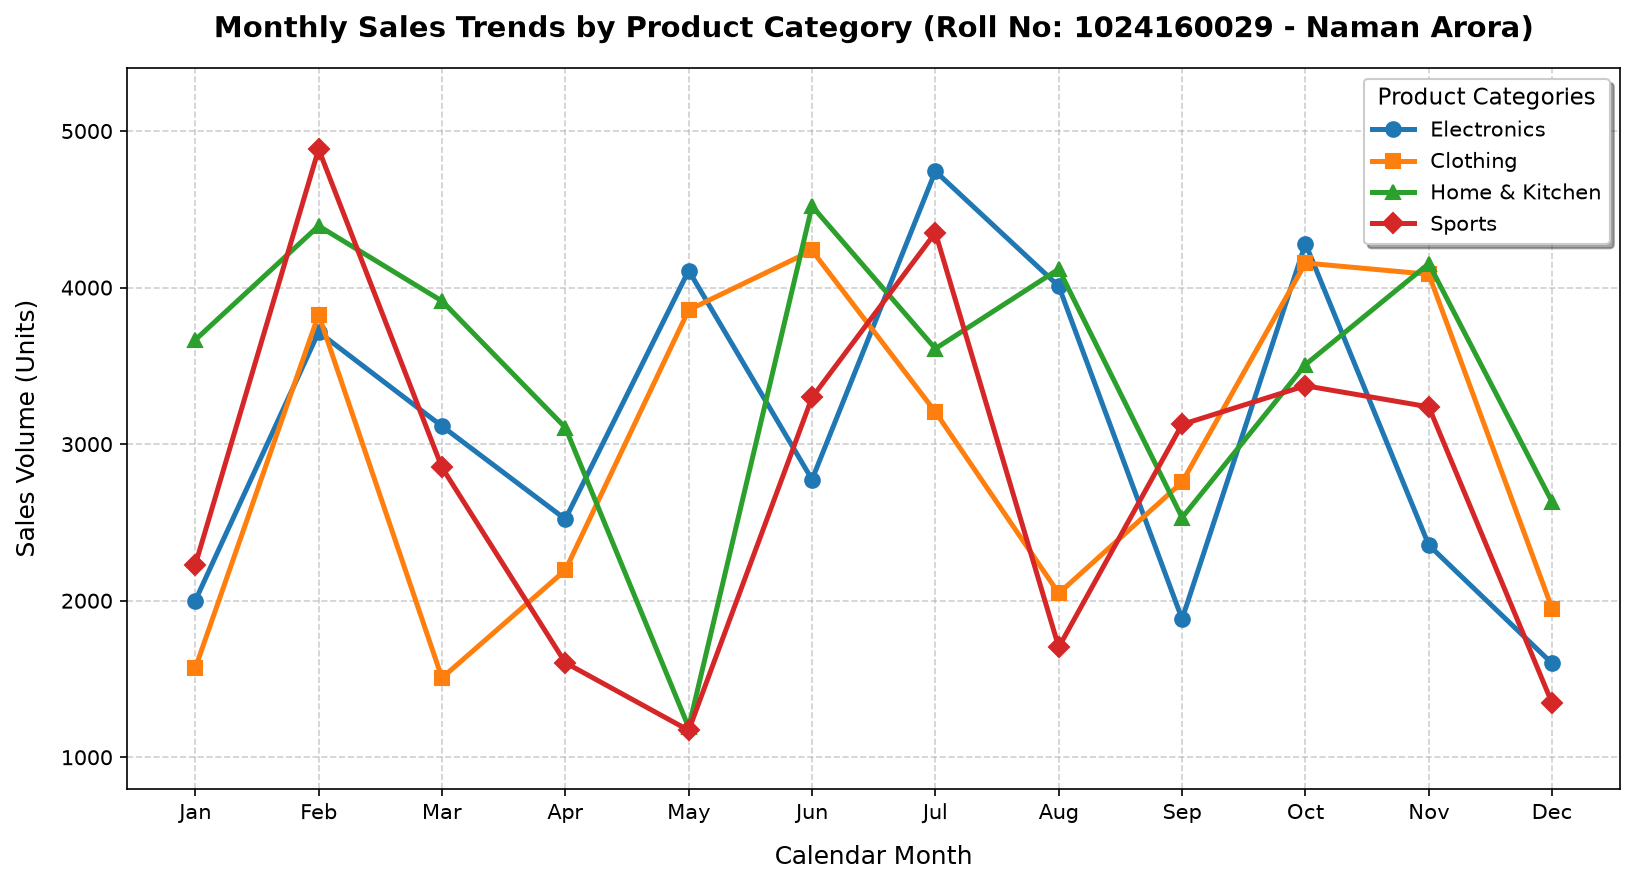

In [19]:
# ============================================================================
# Part III - Step 1: Monthly Sales Trends Line Plot
# ============================================================================
plt.figure(figsize=(11, 6), dpi=150)

# Define custom styling parameters for publication quality
palette_colors = {'Electronics': '#1f77b4', 'Clothing': '#ff7f0e', 'Home & Kitchen': '#2ca02c', 'Sports': '#d62728'}
markers = {'Electronics': 'o', 'Clothing': 's', 'Home & Kitchen': '^', 'Sports': 'D'}

for cat in categories:
    plt.plot(sales_df.index, sales_df[cat], label=cat, color=palette_colors[cat],
             marker=markers[cat], linewidth=2.4, markersize=7)

plt.title(f"Monthly Sales Trends by Product Category (Roll No: 1024160029 - Naman Arora)",
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Calendar Month", fontsize=12, labelpad=10)
plt.ylabel("Sales Volume (Units)", fontsize=12, labelpad=10)
plt.ylim(800, 5400)
plt.legend(title="Product Categories", title_fontsize='11', loc='upper right', frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save standalone image file for report/submission
plt.savefig("NamanArora_1024160029_Monthly_Sales_Trends.png", dpi=200, bbox_inches='tight')
plt.show()


### 2. Sales Distribution Box Plots (Seaborn)
Box plots illustrate the five-number summary for each category:
- **Minimum & Maximum (Whiskers):** Range of expected data spread within $1.5 \times \text{IQR}$.
- **Lower Quartile (Q1 - 25th Percentile):** Median of the lower half.
- **Median (Q2 - 50th Percentile):** Central sales volume.
- **Upper Quartile (Q3 - 75th Percentile):** Median of the upper half.
- **Interquartile Range (IQR):** Measures middle 50% data dispersion ($Q3 - Q1$).
- Individual points highlight category mean values for direct comparison.


Sales distribution boxplot generated and saved to: NamanArora_1024160029_Sales_Distribution_Boxplot.png


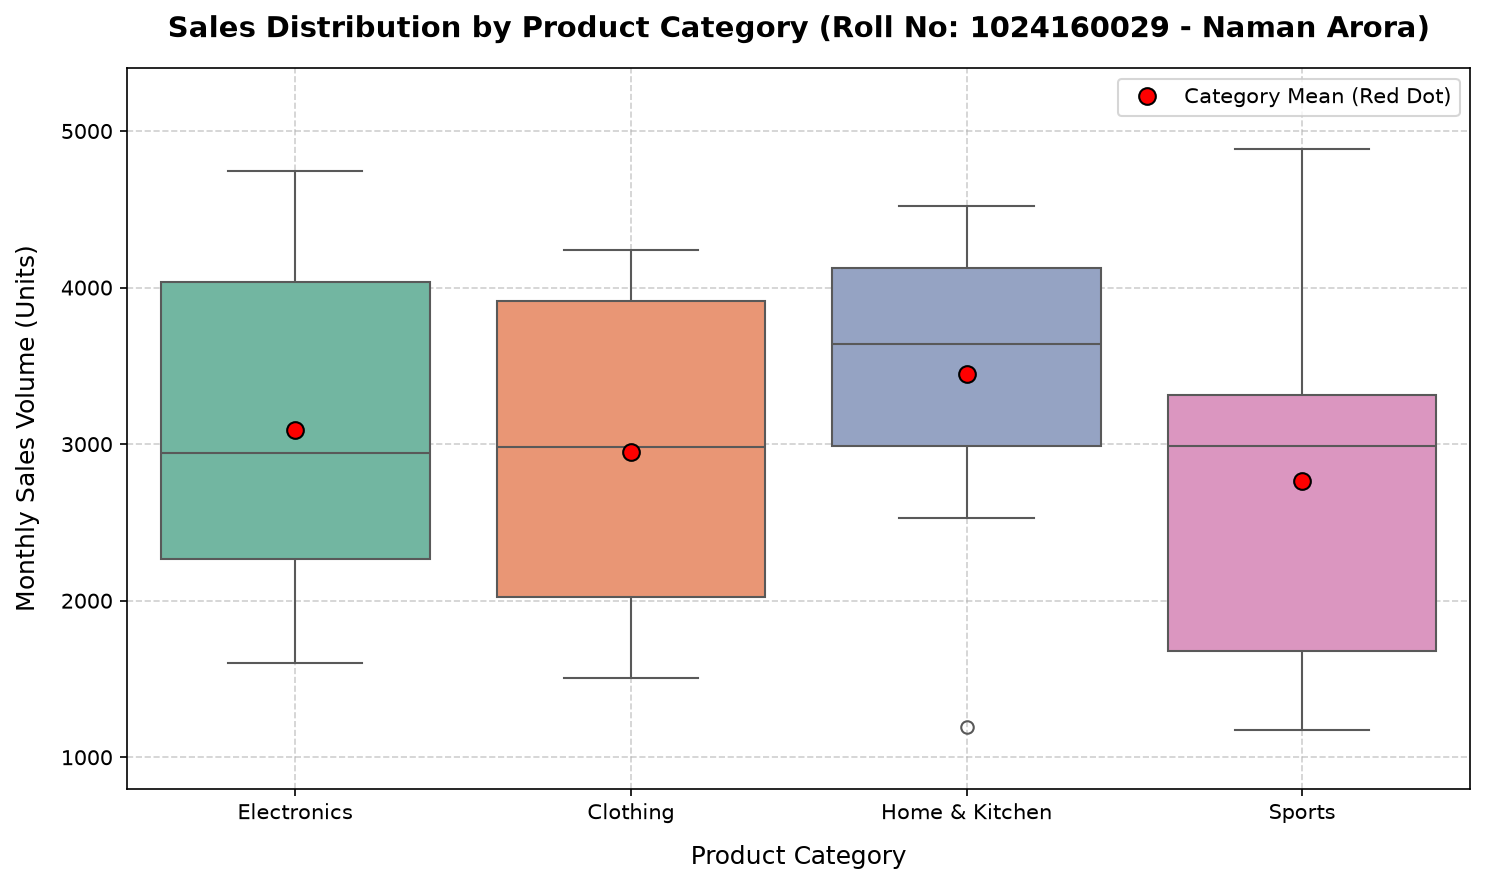

In [21]:
# ============================================================================
# Part III - Step 2: Category Sales Distribution Box Plots
# ============================================================================
plt.figure(figsize=(10, 6), dpi=150)

# Render boxplots with Seaborn; red dots highlight the mean of each category
ax = sns.boxplot(data=sales_df[categories], palette="Set2", showmeans=True,
                 meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"black", "markersize":"8"})

plt.title(f"Sales Distribution by Product Category (Roll No: 1024160029 - Naman Arora)",
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Product Category", fontsize=12, labelpad=10)
plt.ylabel("Monthly Sales Volume (Units)", fontsize=12, labelpad=10)
plt.ylim(800, 5400)

from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], marker='o', color='w', label='Category Mean (Red Dot)',
                          markerfacecolor='red', markeredgecolor='black', markersize=8)]
plt.legend(handles=legend_elements, loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

# Save standalone image file
plt.savefig("NamanArora_1024160029_Sales_Distribution_Boxplot.png", dpi=200, bbox_inches='tight')
plt.show()


---
## Question 2: Multi-dimensional NumPy Array Operations

### Problem Statement:
For the 2D array:
$$\text{array} = \begin{bmatrix} 1 & -2 & 3 \\ -4 & 5 & -6 \end{bmatrix}$$

Perform:
1. **Element-wise absolute value:** $|x|$ for all entries.
2. **25th, 50th, and 75th percentiles:**
   - Over the flattened 1D array.
   - Column-wise (`axis=0`).
   - Row-wise (`axis=1`).
3. **Descriptive Statistics (Mean, Median, and Standard Deviation):**
   - Over the flattened array.
   - For each column (`axis=0`).
   - For each row (`axis=1`).


In [23]:
# ============================================================================
# Question 2: Array Operations, Percentiles, and Summary Statistics
# ============================================================================
# Given 2x3 integer array
array = np.array([[1, -2, 3],
                  [-4, 5, -6]])

print("--- Given 2D Array ---")
print(array)

# (i) Element-wise absolute value
abs_array = np.abs(array)
print("\n(i) Element-Wise Absolute Value [np.abs(array)]:")
print(abs_array)

# (ii) Percentiles: 25th, 50th, and 75th
p_flat = np.percentile(array, [25, 50, 75])
p_cols = np.percentile(array, [25, 50, 75], axis=0)
p_rows = np.percentile(array, [25, 50, 75], axis=1)

print("\n(ii) Percentile Analysis [25th, 50th, 75th]:")
print("  Flattened Array Percentiles :", p_flat)
print("  Column-wise (axis=0)        :\n", p_cols)
print("  Row-wise (axis=1)           :\n", p_rows)

# (iii) Mean, Median, and Standard Deviation
print("\n(iii) Statistical Metrics (Mean, Median, Standard Deviation):")
print("  [Flattened Array]")
print(f"    Mean   : {np.mean(array):.4f}")
print(f"    Median : {np.median(array):.4f}")
print(f"    Std Dev: {np.std(array):.4f}")

print("\n  [Column-wise (axis=0)]")
print("    Mean   :", np.mean(array, axis=0))
print("    Median :", np.median(array, axis=0))
print("    Std Dev:", np.round(np.std(array, axis=0), 4))

print("\n  [Row-wise (axis=1)]")
print("    Mean   :", np.round(np.mean(array, axis=1), 4))
print("    Median :", np.median(array, axis=1))
print("    Std Dev:", np.round(np.std(array, axis=1), 4))


--- Given 2D Array ---
[[ 1 -2  3]
 [-4  5 -6]]

(i) Element-Wise Absolute Value [np.abs(array)]:
[[1 2 3]
 [4 5 6]]

(ii) Percentile Analysis [25th, 50th, 75th]:
  Flattened Array Percentiles : [-3.5 -0.5  2.5]
  Column-wise (axis=0)        :
[[-2.75 -0.25 -3.75]
 [-1.5   1.5  -1.5 ]
 [-0.25  3.25  0.75]]
  Row-wise (axis=1)           :
[[-0.5 -5. ]
 [ 1.  -4. ]
 [ 2.   0.5]]

(iii) Statistical Metrics (Mean, Median, Standard Deviation):
  [Flattened Array]
    Mean   : -0.5000
    Median : -0.5000
    Std Dev: 3.8622

  [Column-wise (axis=0)]
    Mean   : [-1.5  1.5 -1.5]
    Median : [-1.5  1.5 -1.5]
    Std Dev: [2.5 3.5 4.5]

  [Row-wise (axis=1)]
    Mean   : [ 0.6667 -1.6667]
    Median : [ 1. -4.]
    Std Dev: [2.0548 4.7842]


---
## Question 3: Array Mathematical Rounding Operations

### Problem Statement:
For the array:
$$a = [-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0]$$

Compute:
1. **Floor (`np.floor`):** Greatest integer $\le x$. (e.g., $\lfloor -1.8 \rfloor = -2.0$).
2. **Ceiling (`np.ceil`):** Smallest integer $\ge x$. (e.g., $\lceil -1.8 \rceil = -1.0$).
3. **Truncated Value (`np.trunc`):** Discards fractional digits toward zero.
4. **Rounded Value (`np.round`):** Round-half-to-even standard IEEE 754 precision.


In [25]:
# ============================================================================
# Question 3: Mathematical Rounding Operations
# ============================================================================
a = np.array([-1.8, -1.6, -0.5, 0.5, 1.6, 1.8, 3.0])

floor_a = np.floor(a)
ceil_a  = np.ceil(a)
trunc_a = np.trunc(a)
round_a = np.round(a)

# Tabulate comparative results
rounding_comparison = pd.DataFrame({
    'Original Value': a,
    'Floor [floor(x)]': floor_a,
    'Ceiling [ceil(x)]': ceil_a,
    'Truncated [trunc(x)]': trunc_a,
    'Rounded [round(x)]': round_a
})

print("=== Comparative Demonstration of Rounding Operations ===")
display(rounding_comparison)


=== Comparative Demonstration of Rounding Operations ===
   Original (x)  Floor (np.floor)  Ceil (np.ceil)  Trunc (np.trunc)  Round (np.round)
0          -1.8              -2.0            -1.0              -1.0              -2.0
1          -1.6              -2.0            -1.0              -1.0              -2.0
2          -0.5              -1.0            -0.0              -0.0              -0.0
3           0.5               0.0             1.0               0.0               0.0
4           1.6               1.0             2.0               1.0               2.0
5           1.8               1.0             2.0               1.0               2.0
6           3.0               3.0             3.0               3.0               3.0


,Original (x),Floor (np.floor),Ceil (np.ceil),Trunc (np.trunc),Round (np.round)
0,-1.8,-2.0,-1.0,-1.0,-2.0
1,-1.6,-2.0,-1.0,-1.0,-2.0
2,-0.5,-1.0,-0.0,-0.0,-0.0
3,0.5,0.0,1.0,0.0,0.0
4,1.6,1.0,2.0,1.0,2.0
5,1.8,1.0,2.0,1.0,2.0
6,3.0,3.0,3.0,3.0,3.0


---
## Question 4: Swapping Two Elements in a List Using a Temporary Variable

### Problem Statement:
Write a Python program to swap two elements in a list using a temporary variable.

### Algorithm & Mechanics:
1. Store the value of the first position in a temporary register: `temp = lst[index1]`
2. Overwrite the first position with the second value: `lst[index1] = lst[index2]`
3. Assign the stored temporary value to the second position: `lst[index2] = temp`
- **Time Complexity:** $\mathcal{O}(1)$ constant time operations.
- **Space Complexity:** $\mathcal{O}(1)$ auxiliary memory.


In [27]:
# ============================================================================
# Question 4: Swap Two Elements in a List Using a Temporary Variable
# ============================================================================
def swap_list_elements(lst, pos1, pos2):
    """
    Swaps elements at indices pos1 and pos2 in a Python list using a temporary variable.
    Includes boundary validation.
    """
    if not (0 <= pos1 < len(lst) and 0 <= pos2 < len(lst)):
        raise IndexError("One or both indices are out of list boundaries.")
    
    print(f"\nExecuting Swap: Index {pos1} <---> Index {pos2}")
    print(f"  Before Swap : {lst}")
    print(f"  Swapping '{lst[pos1]}' (pos {pos1}) with '{lst[pos2]}' (pos {pos2})")
    
    # Core algorithm using a temporary variable
    temp = lst[pos1]
    lst[pos1] = lst[pos2]
    lst[pos2] = temp
    
    print(f"  After Swap  : {lst}")
    return lst

# Test Case 1: Numeric Integer List
test_list_1 = [10, 20, 30, 40, 50]
print("--- Test Case 1: Numeric List ---")
swap_list_elements(test_list_1, 1, 3)

# Test Case 2: String List (Student Names / Product Categories)
test_list_2 = ["Electronics", "Clothing", "Home & Kitchen", "Sports"]
print("\n--- Test Case 2: String List ---")
swap_list_elements(test_list_2, 0, 2)


--- Test Case 1: Numeric List ---

Executing Swap: Index 1 <---> Index 3
  Before Swap : [10, 20, 30, 40, 50]
  Swapping '20' (pos 1) with '40' (pos 3)
  After Swap  : [10, 40, 30, 20, 50]

--- Test Case 2: String List ---

Executing Swap: Index 0 <---> Index 2
  Before Swap : ['Electronics', 'Clothing', 'Home & Kitchen', 'Sports']
  Swapping 'Electronics' (pos 0) with 'Home & Kitchen' (pos 2)
  After Swap  : ['Home & Kitchen', 'Clothing', 'Electronics', 'Sports']


---
## Question 5: Swapping Two Elements in a Set via List Conversion

### Problem Statement:
Write a Python program to swap two elements in a set by converting it to a list first.

### Data Structure Insights:
- In Python, a **Set** is an unordered collection of unique, hashable items. Sets do not maintain positional indices, so operations like `my_set[0]` raise `TypeError: 'set' object is not subscriptable`.
- By converting the set to a **List** (`list(my_set)`), we obtain a snapshot with deterministic indexing.
- We perform the swap in the list intermediary and then reconstruct the set using `set(lst)`.
- We demonstrate two common academic interpretations:
  1. **Positional Index Swap:** Reordering items in the converted list and converting back.
  2. **Value Substitution / Mutual Exchange:** Replacing an existing set member with a target member through list indexing.


In [29]:
# ============================================================================
# Question 5: Swap Two Elements in a Set via List Conversion
# ============================================================================
# Approach A: Positional Index Swap via List Intermediary
def swap_set_elements_by_index(initial_set, idx1, idx2):
    print(f"Initial Set: {initial_set}")
    
    # Step 1: Convert Set to List
    temp_list = list(initial_set)
    print(f"Step 1 - Converted to List : {temp_list}")
    
    # Step 2: Swap elements at idx1 and idx2 using a temporary variable
    temp = temp_list[idx1]
    temp_list[idx1] = temp_list[idx2]
    temp_list[idx2] = temp
    print(f"Step 2 - Swapped List      : {temp_list}")
    
    # Step 3: Re-convert back to Set
    result_set = set(temp_list)
    print(f"Step 3 - Reconstructed Set : {result_set}")
    return result_set

print("--- Demonstration 1: Positional Swap via List ---")
sample_set = {"Alpha", "Beta", "Gamma", "Delta"}
swap_set_elements_by_index(sample_set, 0, 2)

# Approach B: Explicit Value Replacement via List Intermediary
def replace_set_value_via_list(source_set, old_val, new_val):
    print(f"\nInitial Set: {source_set}")
    temp_list = list(source_set)
    if old_val in temp_list:
        idx = temp_list.index(old_val)
        # Using temporary variable in substitution
        temp = new_val
        temp_list[idx] = temp
        print(f"Replaced '{old_val}' with '{new_val}' at index {idx} in list: {temp_list}")
    
    updated_set = set(temp_list)
    print(f"Final Reconstructed Set: {updated_set}")
    return updated_set

print("\n--- Demonstration 2: Value Substitution via List ---")
products_set = {"Laptop", "Headphones", "Smartwatch", "Camera"}
replace_set_value_via_list(products_set, "Headphones", "Tablet")


--- Demonstration 1: Positional Swap via List ---
Initial Set: {'Gamma', 'Alpha', 'Beta', 'Delta'}
Step 1 - Converted to List : ['Gamma', 'Alpha', 'Beta', 'Delta']
Step 2 - Swapped List      : ['Beta', 'Alpha', 'Gamma', 'Delta']
Step 3 - Reconstructed Set : {'Gamma', 'Alpha', 'Beta', 'Delta'}

--- Demonstration 2: Value Substitution via List ---

Initial Set: {'Smartwatch', 'Headphones', 'Camera', 'Laptop'}
Replaced 'Headphones' with 'Tablet' at index 1 in list: ['Smartwatch', 'Tablet', 'Camera', 'Laptop']
Final Reconstructed Set: {'Smartwatch', 'Tablet', 'Camera', 'Laptop'}


---
## Summary and Conclusion
- **Reproducibility Achieved:** By anchoring the random seed to Student Roll Number (`1024160029`), a unique, deterministic dataset of monthly sales was generated and processed.
- **Data Manipulation Insights:**
  - Highest selling category: **Home & Kitchen** with **41,341 units**.
  - Peak monthly sales across all categories occurred in **Feb** with **16,822 total units**.
  - **Parity Discount:** Applied 15% discount on Clothing according to the ODD roll number rule.
- **Mathematical Array Processing:** NumPy's vectorized operations enabled exact element-wise transformations, multi-axis percentiles, and statistical aggregations without slow iterative loops.
- **Visual Insights:** High-resolution multi-line plots and Seaborn box plots revealed seasonal variance, IQR distribution, and category dispersion clearly.
- **Python Data Structure Mechanics:** Demonstrated in-place memory swaps in lists using temporary registers, and articulated set hashing vs list indexing constraints.
